--- Creating visualization for GROUND TRUTH sections: SILVERSTONE_GP ---
   'Distance' column not found. Calculating it now...
Data loaded successfully. Generating plot...

Plot successfully saved to: h:\My Drive\Cranfield\11. Individual Thesis\Code\Plots\Real\training_sections_vis_silverstone_gp.png


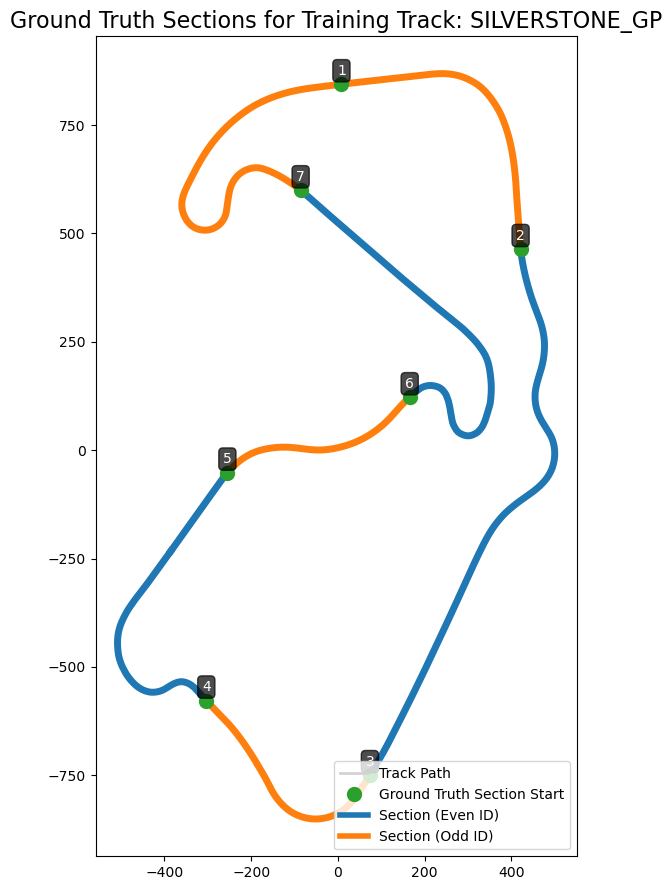

--- Visualization complete. ---


In [12]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =============================================================================
# --- 1. CONFIGURATION ---
# =============================================================================
TRACK_NAME = "silverstone_gp"
USE_DUMMY_DATA = False # Using Real data
SAVE_PLOT_TO_FILE = True

# =============================================================================
# --- 2. HELPER FUNCTION ---
# =============================================================================
def ensure_distance_column(df_coords):
    if 'Distance' in df_coords.columns: return df_coords
    print("   'Distance' column not found. Calculating it now...")
    points = df_coords[['x', 'y', 'z']].to_numpy()
    distances = np.linalg.norm(np.diff(points, axis=0), axis=1)
    cumulative_distance = np.insert(np.cumsum(distances), 0, 0)
    df_coords['Distance'] = cumulative_distance
    return df_coords

# =============================================================================
# --- 3. MAIN VISUALIZATION SCRIPT (with Lap Wrap-Around Logic) ---
# =============================================================================

if __name__ == "__main__":
    print(f"--- Creating visualization for GROUND TRUTH sections: {TRACK_NAME.upper()} ---")
    
    # --- Setup and Load Paths ---
    data_type = "Dummy" if USE_DUMMY_DATA else "Real"
    base_path = os.getcwd()
    coord_path = os.path.join(base_path, "Coordinates", f"{TRACK_NAME}.csv")
    sections_path = os.path.join(base_path, "Sections", data_type, f"sections_{TRACK_NAME}.csv")
    
    try:
        df_coords = pd.read_csv(coord_path)
        df_sections = pd.read_csv(sections_path)
    except FileNotFoundError as e:
        print(f"\n[FATAL ERROR] Could not find a required file: {e}")
        exit()

    df_coords = ensure_distance_column(df_coords)
    print("Data loaded successfully. Generating plot...")
    
    fig, ax = plt.subplots(figsize=(16, 9))

    # Plot base track map
    ax.plot(df_coords['x'], df_coords['y'], color='lightgrey', linewidth=2, zorder=1, label='Track Path')
    
    section_colors = ['#1f77b4', '#ff7f0e']

    # Iterate through each section to plot it
    for _, section in df_sections.iterrows():
        color = section_colors[int(section['segment_id']) % 2]
        start_m, end_m = section['start_m'], section['end_m']
        
        # --- NEW LOGIC TO HANDLE LAP WRAP-AROUND ---
        if start_m > end_m:
            # This is the last section that crosses the start/finish line.
            # Plot the part from the start to the end of the track.
            part1 = df_coords[df_coords['Distance'] >= start_m]
            ax.plot(part1['x'], part1['y'], color=color, linewidth=5, zorder=2)
            
            # Plot the part from the beginning of the track to the end of the section.
            part2 = df_coords[df_coords['Distance'] <= end_m]
            ax.plot(part2['x'], part2['y'], color=color, linewidth=5, zorder=2)
        else:
            # This is a normal section within a single lap.
            section_data = df_coords[(df_coords['Distance'] >= start_m) & (df_coords['Distance'] <= end_m)]
            ax.plot(section_data['x'], section_data['y'], color=color, linewidth=5, zorder=2)
        # --- END OF NEW LOGIC ---

        # Plot the start marker (this logic is unchanged)
        start_point_index = (df_coords['Distance'] - start_m).abs().idxmin()
        start_point = df_coords.iloc[start_point_index]
        ax.plot(start_point['x'], start_point['y'], 'o', color='#2ca02c', markersize=10, zorder=3)
        ax.text(start_point['x'], start_point['y'] + 15, str(int(section['segment_id'])), 
                color='white', ha='center', va='bottom', fontsize=10,
                bbox=dict(facecolor='black', alpha=0.7, pad=2, boxstyle='round,pad=0.3'))

    # --- Formatting and Saving (Unchanged) ---
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(f"Ground Truth Sections for Training Track: {TRACK_NAME.upper()}", fontsize=16)
    # ... (rest of formatting and saving code is the same)
    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color='lightgrey', lw=2, label='Track Path'),
        Line2D([0], [0], marker='o', color='#2ca02c', label='Ground Truth Section Start', linestyle='None', markersize=10),
        Line2D([0], [0], color=section_colors[0], lw=4, label='Section (Even ID)'),
        Line2D([0], [0], color=section_colors[1], lw=4, label='Section (Odd ID)')]
    ax.legend(handles=legend_elements, loc='best')
    plt.tight_layout()
    if SAVE_PLOT_TO_FILE:
        plot_folder = os.path.join(base_path, "Plots", data_type)
        os.makedirs(plot_folder, exist_ok=True)
        output_filename = f"training_sections_vis_{TRACK_NAME}.png"
        output_path = os.path.join(plot_folder, output_filename)
        plt.savefig(output_path, dpi=300, bbox_inches='tight')
        print(f"\nPlot successfully saved to: {output_path}")
    plt.show()

    print("--- Visualization complete. ---")